# Bank Marketing – Klassifikation

Ziel: vorhersagen, ob ein Kontakt ein Festgeld abschließt, und daraus eine Anrufliste für die Bank machen.

## 1. Methode

Baummodelle erfassen Wechselwirkungen und kommen mit schiefen Daten klar; die logistische Regression ist einfach zu erklären.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score)

# Matplotlib setting for Jupyter Notebook
%matplotlib inline

# Versionsstand dokumentieren (Reproduzierbarkeit)
import platform, sklearn
print(f"Python {platform.python_version()} · pandas {pd.__version__} · scikit-learn {sklearn.__version__}")

Python 3.12.7 · pandas 2.2.2 · scikit-learn 1.5.1


## 2. Daten laden und Leakage-Spalte entfernen

In [2]:
# Setze den relativen Pfad zur Datei
dateipfad = os.path.join("..", "data", "processed", "bank_marketing_processed.csv")
IMAGE_DIR = os.path.join("..", "images")
RESULT_DIR = os.path.join("..", "results")

df = pd.read_csv(dateipfad)

# Entfernen von Spalten mit Dataleakage, also Spalten, die vor dem Anruf noch nicht bekannt sind
notinuse_col = ['duration']   # Gesprächsdauer: erst NACH dem Anruf bekannt

df.drop(notinuse_col, axis=1, inplace=True)

In [3]:
# Vollständige Übersicht aller Variablen mit Eigenschaften und Datentypen
print(f"Anzahl der Spalten: {len(df.columns)}")
print(f"Anzahl der Zeilen: {len(df)}")

variable_info = pd.DataFrame({
    'Variable': df.columns,
    'Datentyp': df.dtypes.astype(str).values,
    'Fehlend': df.isna().sum().values,
    'Unique': [df[col].nunique() for col in df.columns]
})
print(variable_info.to_string(index=False))

Anzahl der Spalten: 20
Anzahl der Zeilen: 41188
            Variable Datentyp  Fehlend  Unique
                 age    int64        0      78
                 job   object        0      12
             marital   object        0       4
           education   object        0       8
             default   object        0       3
             housing   object        0       3
                loan   object        0       3
             contact   object        0       2
               month   object        0      10
         day_of_week   object        0       5
            campaign    int64        0      42
            previous    int64        0       8
            poutcome   object        0       3
        emp.var.rate  float64        0      10
      cons.price.idx  float64        0      26
       cons.conf.idx  float64        0      26
           euribor3m  float64        0     316
         nr.employed  float64        0      11
                   y    int64        0       2
previously_c

**Interpretation:** *duration* ist entfernt, weil sie erst nach dem Anruf bekannt ist; es gibt keine fehlenden Werte.

## 3. One-Hot-Encoding

In [4]:
# Identifikation der kategorischen Variablen
categorical_cols = df.select_dtypes(exclude=['number']).columns.tolist()
print("Kategoriale Spalten:", categorical_cols)

# One-hot encoding for categorical variables
for var in categorical_cols:
    dummies = pd.get_dummies(df[var], prefix=var, dtype=int)
    df = pd.concat([df, dummies], axis=1)
    df.drop(var, axis=1, inplace=True)

print(f"\nNach der Kodierung: {df.shape[1]} Spalten")

Kategoriale Spalten: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']



Nach der Kodierung: 63 Spalten


**Interpretation:** Aus 10 Textspalten werden 0/1-Spalten, insgesamt 62 Merkmale.

## 4. Train/Test-Split

In [5]:
# --------------------------------------------------------------------
# 1) Feature-Matrix und Zielvariable definieren
# --------------------------------------------------------------------
X = df.drop('y', axis=1)  # alle Merkmale außer der Zielvariable
y = df['y']               # 1 = Festgeldabschluss, 0 = kein Abschluss

In [6]:
# --------------------------------------------------------------------
# 2) Aufteilen in Trainings- und Testset
# --------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Stratifizierung empfohlen bei Klassifikation
)

print(f"Training: {X_train.shape[0]} Zeilen · Test: {X_test.shape[0]} Zeilen")
print(f"Anteil Abschlüsse im Training: {y_train.mean():.2%} · im Test: {y_test.mean():.2%}")

Training: 32950 Zeilen · Test: 8238 Zeilen
Anteil Abschlüsse im Training: 11.27% · im Test: 11.26%


**Interpretation:** 80 % Training und 20 % Test, beide mit 11,3 % Abschlüssen.

## 5. Hilfsfunktionen

Die Funktionen bewerten alle Modelle gleich und rechnen den Nutzen der Anrufliste aus.

In [7]:
def bewerte_modell(name, y_true, y_proba, cv_auc=np.nan, cv_std=np.nan):
    """Kennzahlen für ein Modell. y_proba = vorhergesagte Wahrscheinlichkeit für einen Abschluss."""
    y_pred = (y_proba >= 0.5).astype(int)  # Standardschwelle 0,5 wie im Kurs
    return {
        'Modell': name,
        'CV ROC-AUC (Mittel)': cv_auc,
        'CV ROC-AUC (Std.)': cv_std,
        'Test ROC-AUC': roc_auc_score(y_true, y_proba),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
    }


def top_auswahl(y_true, y_proba, anteil):
    """Die Bank ruft nur die besten `anteil` (z. B. 0.2 = 20 %) der Liste an."""
    liste = pd.DataFrame({'y': np.asarray(y_true), 'p': y_proba}).sort_values('p', ascending=False)
    anzahl = int(round(anteil * len(liste)))
    auswahl = liste.head(anzahl)
    quote = auswahl['y'].mean()
    return {
        'Angerufen': f"{anteil:.0%}",
        'Anrufe': anzahl,
        'Abschlüsse': int(auswahl['y'].sum()),
        'Abschlussquote': quote,
        'Lift (vs. Zufall)': quote / liste['y'].mean(),
        'Anteil aller Abschlüsse': auswahl['y'].sum() / liste['y'].sum(),
    }


def cv_ergebnis(grid_search):
    """Mittelwert und Standardabweichung des besten Modells aus der Kreuzvalidierung."""
    i = grid_search.best_index_
    return grid_search.cv_results_['mean_test_score'][i], grid_search.cv_results_['std_test_score'][i]


ergebnisse = []   # hier sammeln wir die Kennzahlen aller Modelle
proba_test = {}   # vorhergesagte Wahrscheinlichkeiten im Test je Modell

## 6. Baseline

In [8]:
# --------------------------------------------------------------------
# 3) Baseline
# --------------------------------------------------------------------
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

proba_test['Baseline'] = baseline.predict_proba(X_test)[:, 1]
ergebnisse.append(bewerte_modell('Baseline', y_test, proba_test['Baseline'], cv_auc=0.5, cv_std=0.0))
pd.DataFrame(ergebnisse).round(4)

,Modell,CV ROC-AUC (Mittel),CV ROC-AUC (Std.),Test ROC-AUC,Accuracy,Precision,Recall,F1
0,Baseline,0.5,0.0,0.5,0.8874,0.0,0.0,0.0


**Interpretation:** Die Baseline hat 88,7 % Accuracy, findet aber keinen einzigen Abschluss – Accuracy allein täuscht.

## 7. Entscheidungsbaum mit GridSearchCV

In [9]:
# --------------------------------------------------------------------
# 4) Klassifikationsbaum + Hyperparameter-Tuning mit GridSearchCV
# --------------------------------------------------------------------
classifier = DecisionTreeClassifier(random_state=42)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [1, 10, 50]
}

grid_tree = GridSearchCV(
    estimator=classifier,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    scoring='roc_auc'
)
grid_tree.fit(X_train, y_train)

best_tree = grid_tree.best_estimator_
cv_auc, cv_std = cv_ergebnis(grid_tree)
print("Beste Hyperparameter:", grid_tree.best_params_)
print(f"Bester CV-Score (ROC-AUC): {cv_auc:.4f} (Std. {cv_std:.4f})")

proba_test['Entscheidungsbaum'] = best_tree.predict_proba(X_test)[:, 1]
ergebnisse.append(bewerte_modell('Entscheidungsbaum', y_test, proba_test['Entscheidungsbaum'], cv_auc, cv_std))

Beste Hyperparameter: {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 10}
Bester CV-Score (ROC-AUC): 0.7822 (Std. 0.0090)


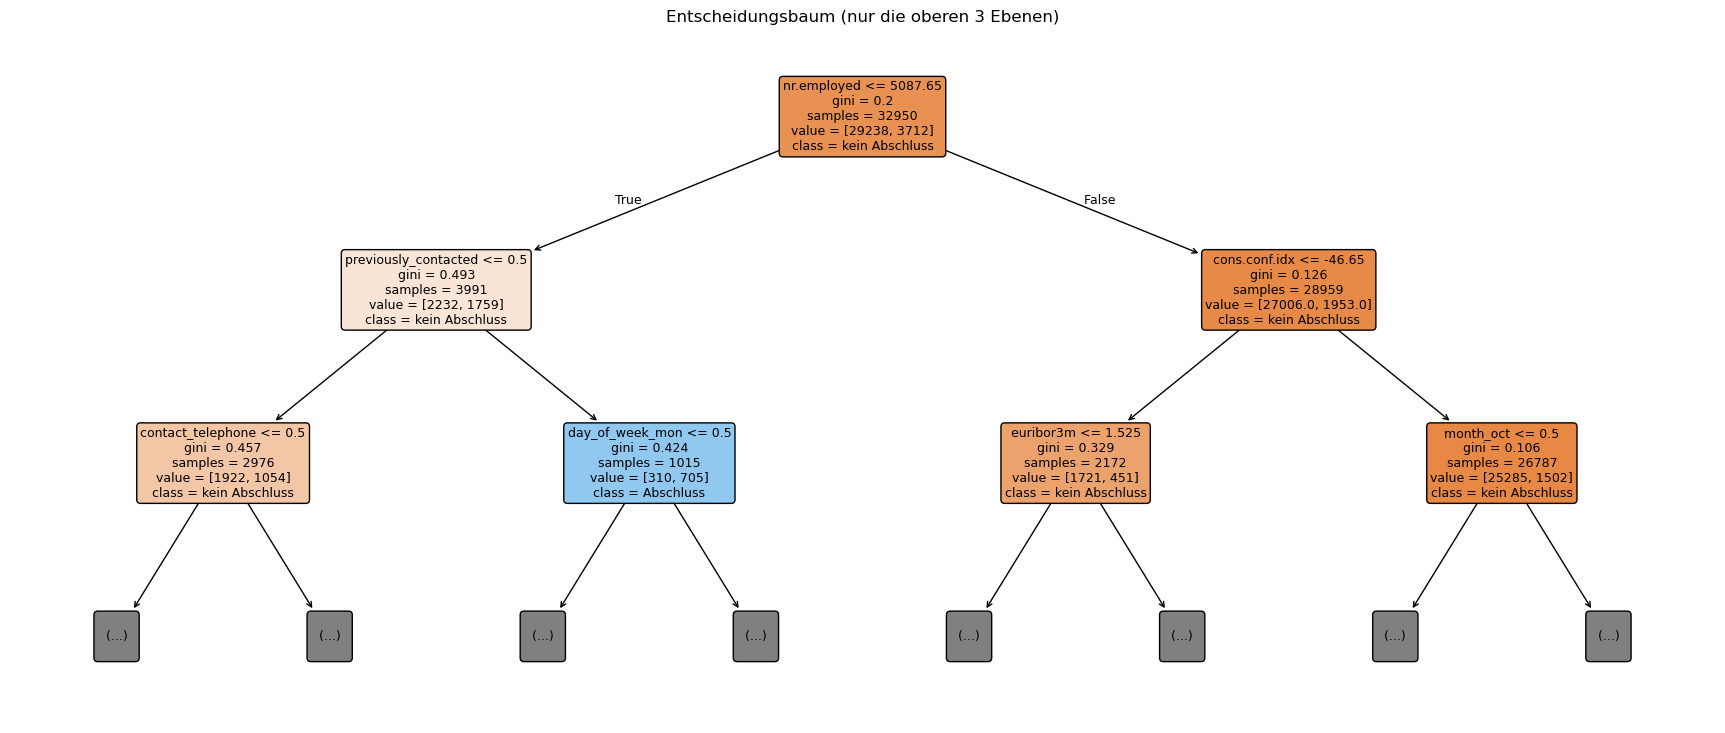

In [10]:
# --------------------------------------------------------------------
# 5) Entscheidungsbaum visualisieren (obere Ebenen)
# --------------------------------------------------------------------
plt.figure(figsize=(22, 9))
plot_tree(best_tree, filled=True, feature_names=X.columns, class_names=["kein Abschluss", "Abschluss"],
          max_depth=2, rounded=True, fontsize=9)
plt.title("Entscheidungsbaum (nur die oberen 3 Ebenen)")
plt.show()

**Interpretation:** Der beste Baum (Tiefe 7) erreicht eine ROC-AUC von 0,782 in der Kreuzvalidierung.

## 8. Random Forest mit GridSearchCV

In [11]:
# --------------------------------------------------------------------
# 6) Random Forest + Hyperparameter-Tuning mit GridSearchCV
# --------------------------------------------------------------------
forest = RandomForestClassifier(n_estimators=200, random_state=42)

param_grid_rf = {
    'max_depth': [8, 12, None],
    'min_samples_leaf': [1, 5, 20]
}

grid_rf = GridSearchCV(
    estimator=forest,
    param_grid=param_grid_rf,
    cv=5,
    n_jobs=-1,
    scoring='roc_auc'
)
grid_rf.fit(X_train, y_train)  # dauert etwa 1-2 Minuten

best_rf = grid_rf.best_estimator_
cv_auc, cv_std = cv_ergebnis(grid_rf)
print("Beste Hyperparameter:", grid_rf.best_params_)
print(f"Bester CV-Score (ROC-AUC): {cv_auc:.4f} (Std. {cv_std:.4f})")

proba_test['Random Forest'] = best_rf.predict_proba(X_test)[:, 1]
ergebnisse.append(bewerte_modell('Random Forest', y_test, proba_test['Random Forest'], cv_auc, cv_std))

Beste Hyperparameter: {'max_depth': 12, 'min_samples_leaf': 20}
Bester CV-Score (ROC-AUC): 0.7966 (Std. 0.0127)


**Interpretation:** Der beste Random Forest erreicht eine ROC-AUC von 0,797 in der Kreuzvalidierung.

## 9. Logistische Regression mit Skalierung

In [12]:
# --------------------------------------------------------------------
# 7) Skalierung (nur auf dem Training gelernt)
# --------------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # lernt nur aus dem Training
X_test_scaled = scaler.transform(X_test)        # wendet das Gelernte auf den Test an

In [13]:
# --------------------------------------------------------------------
# 8) Logistische Regression + GridSearchCV
# --------------------------------------------------------------------
grid_lr = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000),
    param_grid={'C': [0.01, 0.1, 1, 10]},  # C = Stärke der Regularisierung
    cv=5,
    n_jobs=-1,
    scoring='roc_auc'
)
grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_
cv_auc, cv_std = cv_ergebnis(grid_lr)
print("Beste Hyperparameter:", grid_lr.best_params_)
print(f"Bester CV-Score (ROC-AUC): {cv_auc:.4f} (Std. {cv_std:.4f})")

proba_test['Logistische Regression'] = best_lr.predict_proba(X_test_scaled)[:, 1]
ergebnisse.append(bewerte_modell('Logistische Regression', y_test, proba_test['Logistische Regression'], cv_auc, cv_std))

Beste Hyperparameter: {'C': 0.1}
Bester CV-Score (ROC-AUC): 0.7884 (Std. 0.0110)


**Interpretation:** Die logistische Regression erreicht eine ROC-AUC von 0,788 in der Kreuzvalidierung.

## 10. Modellvergleich

In [14]:
# --------------------------------------------------------------------
# 9) Vergleichstabelle aller Modelle
# --------------------------------------------------------------------
vergleich = pd.DataFrame(ergebnisse).set_index('Modell')
display(vergleich.round(4))

bestes_modell = vergleich['CV ROC-AUC (Mittel)'].idxmax()
print(f"Bestes Modell nach Kreuzvalidierung: {bestes_modell}")

,CV ROC-AUC (Mittel),CV ROC-AUC (Std.),Test ROC-AUC,Accuracy,Precision,Recall,F1
Modell,,,,,,,
Baseline,0.5000,0.0000,0.5000,0.8874,0.0000,0.0000,0.0000
Entscheidungsbaum,0.7822,0.0090,0.8013,0.9018,0.6343,0.3028,0.4099
Random Forest,0.7966,0.0127,0.8123,0.9018,0.7059,0.2198,0.3353
Logistische Regression,0.7884,0.0110,0.8011,0.9020,0.7023,0.2263,0.3423


Bestes Modell nach Kreuzvalidierung: Random Forest


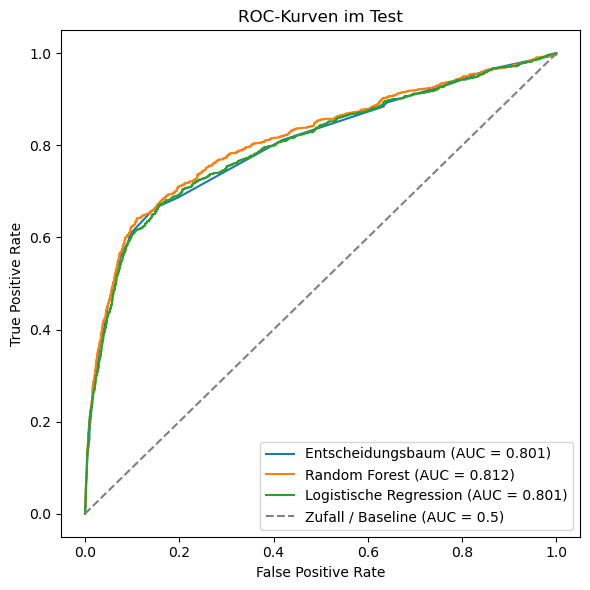

In [15]:
# --------------------------------------------------------------------
# 10) ROC-Kurven und AUC im Test
# --------------------------------------------------------------------
plt.figure(figsize=(6, 6))
for name, proba in proba_test.items():
    if name == 'Baseline':
        continue
    fpr, tpr, thresholds = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Zufall / Baseline (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-Kurven im Test")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "04_roc_kurven.png"), dpi=150)
plt.show()

**Interpretation:** Der Random Forest ist knapp am besten (0,812 im Test), der Vorsprung zu den anderen Modellen ist aber klein.

## 11. Konfusionsmatrix (Schwelle 0,5)

In [16]:
# --------------------------------------------------------------------
# 11) Vorhersagen und Performance-Metriken
# --------------------------------------------------------------------
y_proba_best = proba_test[bestes_modell]
y_pred = (y_proba_best >= 0.5).astype(int)

print(y_test.value_counts())
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix (Schwelle 0,5):\n", cm)

print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

y
0    7310
1     928
Name: count, dtype: int64
Confusion Matrix (Schwelle 0,5):
 [[7225   85]
 [ 724  204]]

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.99      0.95      7310
           1       0.71      0.22      0.34       928

    accuracy                           0.90      8238
   macro avg       0.81      0.60      0.64      8238
weighted avg       0.89      0.90      0.88      8238



**Interpretation:** Bei Schwelle 0,5 findet das Modell nur 204 von 928 Abschlüssen, deshalb zählt die Reihenfolge der Liste.

## 12. Nutzen für die Bank

,Angerufen,Anrufe,Abschlüsse,Abschlussquote,Lift (vs. Zufall),Anteil aller Abschlüsse
0,10%,824,435,0.528,4.686,0.469
1,20%,1648,610,0.370,3.286,0.657
2,30%,2471,687,0.278,2.468,0.740


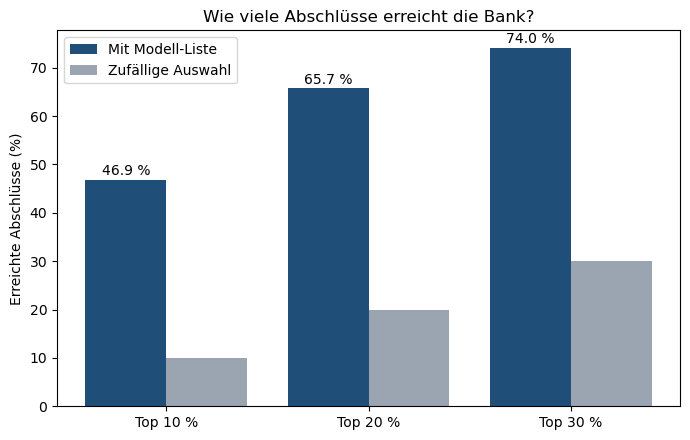

In [17]:
# --------------------------------------------------------------------
# 12) Szenarien 10 %, 20 %, 30 %
# --------------------------------------------------------------------
szenarien = pd.DataFrame([top_auswahl(y_test, y_proba_best, a) for a in [0.1, 0.2, 0.3]])
display(szenarien.round(3))

# Grafik: erreichte Abschlüsse mit Liste vs. Zufall
plt.figure(figsize=(7, 4.5))
x = np.arange(len(szenarien))
plt.bar(x - 0.2, szenarien['Anteil aller Abschlüsse'] * 100, width=0.4, color='#1f4e79', label='Mit Modell-Liste')
plt.bar(x + 0.2, [10, 20, 30], width=0.4, color='#9aa5b1', label='Zufällige Auswahl')
for i, v in enumerate(szenarien['Anteil aller Abschlüsse'] * 100):
    plt.text(i - 0.2, v + 1, f"{v:.1f} %", ha='center')
plt.xticks(x, ['Top 10 %', 'Top 20 %', 'Top 30 %'])
plt.ylabel('Erreichte Abschlüsse (%)')
plt.title('Wie viele Abschlüsse erreicht die Bank?')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "08_kapazitaetsszenarien.png"), dpi=150)
plt.show()

Grenze für die Top 20 %: Wahrscheinlichkeit >= 0.107 (1648 Anrufe)


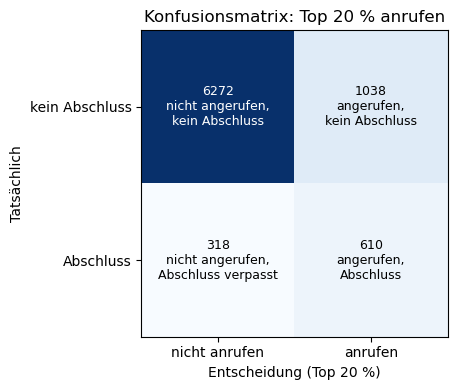

In [18]:
# --------------------------------------------------------------------
# 13) Konfusionsmatrix für die Regel 'die besten 20 % anrufen'
# --------------------------------------------------------------------
anzahl_top20 = int(round(0.2 * len(y_test)))
grenze = np.sort(y_proba_best)[::-1][anzahl_top20 - 1]   # Wahrscheinlichkeit des letzten Kontakts in den Top 20 %
y_pred_top20 = (y_proba_best >= grenze).astype(int)
print(f"Grenze für die Top 20 %: Wahrscheinlichkeit >= {grenze:.3f} ({y_pred_top20.sum()} Anrufe)")

cm_top20 = confusion_matrix(y_test, y_pred_top20)
plt.figure(figsize=(5, 4))
plt.imshow(cm_top20, cmap='Blues')
beschriftung = [['nicht angerufen,\nkein Abschluss', 'angerufen,\nkein Abschluss'],
                ['nicht angerufen,\nAbschluss verpasst', 'angerufen,\nAbschluss']]
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm_top20[i, j]}\n{beschriftung[i][j]}", ha='center', va='center',
                 color='white' if cm_top20[i, j] > cm_top20.max() / 2 else 'black', fontsize=9)
plt.xticks([0, 1], ['nicht anrufen', 'anrufen'])
plt.yticks([0, 1], ['kein Abschluss', 'Abschluss'])
plt.xlabel('Entscheidung (Top 20 %)')
plt.ylabel('Tatsächlich')
plt.title('Konfusionsmatrix: Top 20 % anrufen')
plt.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "05_konfusionsmatrix.png"), dpi=150)
plt.show()

**Interpretation:** Mit den besten 20 % der Liste erreicht die Bank 610 von 928 Abschlüssen (65,7 %), das ist 3,3-mal so gut wie Zufall.

## 13. Wichtigste Merkmale

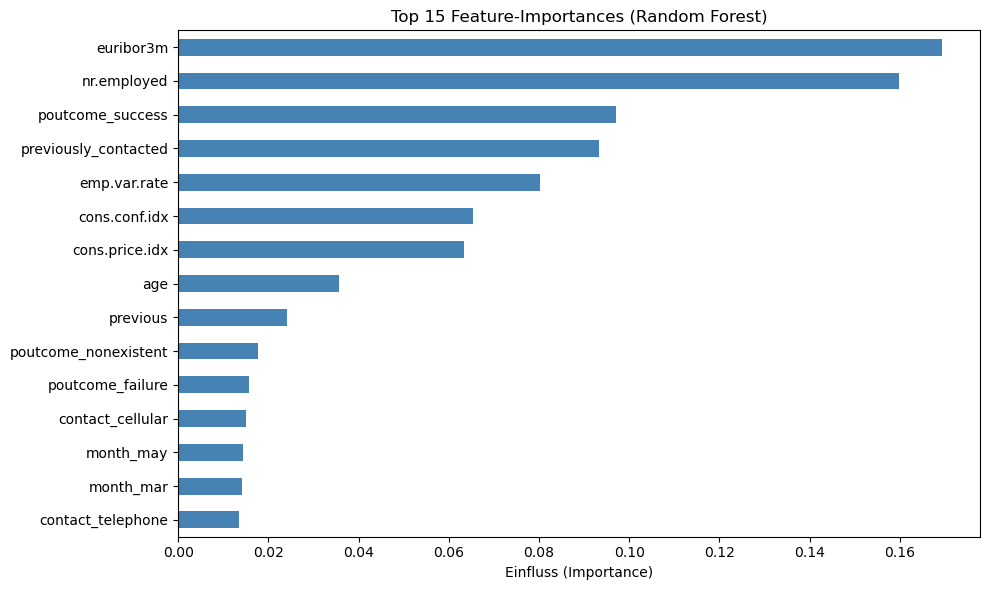

,importance
euribor3m,0.1693
nr.employed,0.1598
poutcome_success,0.0971
previously_contacted,0.0934
emp.var.rate,0.0802
cons.conf.idx,0.0654
cons.price.idx,0.0633
age,0.0356
previous,0.0241
poutcome_nonexistent,0.0177


In [19]:
# --------------------------------------------------------------------
# 14) Feature Importance visualisieren
# --------------------------------------------------------------------
modell_fuer_importance = best_rf if bestes_modell == 'Random Forest' else best_tree
importances = pd.Series(modell_fuer_importance.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(15).sort_values().plot(kind="barh", color="steelblue")
plt.title(f"Top 15 Feature-Importances ({'Random Forest' if modell_fuer_importance is best_rf else 'Entscheidungsbaum'})")
plt.xlabel("Einfluss (Importance)")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "09_wichtigste_merkmale.png"), dpi=150)
plt.show()

importances.head(10).to_frame(name="importance").round(4)

**Interpretation:** Am wichtigsten sind die Wirtschaftszahlen und der Erfolg früherer Kampagnen – das sind Zusammenhänge, keine Ursachen.

## 14. Speichern und Qualitätschecks

In [20]:
# --------------------------------------------------------------------
# 15) Speichern und prüfen
# --------------------------------------------------------------------
vergleich.round(4).to_csv(os.path.join(RESULT_DIR, "modellvergleich.csv"))
szenarien.round(4).to_csv(os.path.join(RESULT_DIR, "szenarien_bestes_modell.csv"), index=False)

# Qualitätschecks
assert len(X_train) + len(X_test) == len(df), "Zeilen gehen verloren"
assert len(set(X_train.index) & set(X_test.index)) == 0, "Training und Test überschneiden sich"
assert 'duration' not in X.columns, "duration darf nicht im Modell sein (Leakage)"
assert vergleich.loc[bestes_modell, 'Test ROC-AUC'] > 0.5, "Modell ist nicht besser als Zufall"
print("Alle Qualitätschecks bestanden. Ergebnisse gespeichert in", RESULT_DIR)

Alle Qualitätschecks bestanden. Ergebnisse gespeichert in ../results


## 15. Fazit

Ein Abschluss lässt sich deutlich besser als zufällig vorhersagen; vor einem echten Einsatz sollte die Bank einen kleinen Pilot machen.